# Single-species group properties: data vs model (group size 16)

One figure, 3 rows x 6 columns (TB16, RB16, BPT16, ST16, NT16, RET16): **individual speed** (BL/s), **polarization** and **nearest-neighbour distance** (NND, BL).
Each panel: real data (orange, solid) with the model for the same species (blue, dashed); y axis = probability density.

* **Data** (`Data/<SP>16_<rep>_traj_bl.npz`, 25 fps): velocity by central difference $\mathbf{v}_i(t) = [\mathbf{x}_i(t+1) - \mathbf{x}_i(t-1)]\,f/2$;
  polarization $m(t) = \left|\frac{1}{n}\sum_i \mathbf{v}_i/|\mathbf{v}_i|\right|$ over the $n$ fish present ($8 \le n \le 16$);
  NND in frames with at least 75 % of the fish tracked. Files with < 1 % valid positions are skipped; RET uses replicates 1-10.
* **Model** (`Data/model_single_species.h5`, 5 runs per species): frames after the transient (`transient_s`); speed = `v`, $m(t) = |\langle e^{i\phi_j}\rangle|$, NND from `x`, `y`.

Saved as `Results/single_species_group_properties_gs16` (PNG and PDF, 300 dpi).

## 1. Settings and functions

In [1]:
%matplotlib inline
import glob, os, re
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

DATA, OUT = os.path.join("..", "Data"), os.path.join("..", "Results")
SPECIES = ["TB", "RB", "BPT", "ST", "NT", "RET"]          # column order
FPS = 25.0


def polarization(vel):
    """|mean unit heading| over the fish present; NaN if fewer than 8 (or more than 16) fish."""
    speed = np.linalg.norm(vel, axis=-1)
    ok = np.isfinite(speed) & (speed > 0)
    e = np.where(ok[..., None], vel / np.where(ok, speed, 1)[..., None], 0.0)
    n = ok.sum(1)
    m = np.linalg.norm(e.sum(1), axis=1) / np.maximum(n, 1)
    m[(n < 8) | (n > 16)] = np.nan
    return m


def nnd(pos, chunk=2000):
    """pos (T, N, 2) -> (T, N) distance to the nearest other tracked fish."""
    out = np.full(pos.shape[:2], np.nan, np.float32)
    for s in range(0, len(pos), chunk):
        D = np.linalg.norm(pos[s:s + chunk, :, None] - pos[s:s + chunk, None], axis=3)
        D[np.isnan(D)] = np.inf
        D[:, np.eye(pos.shape[1], dtype=bool)] = np.inf
        m = D.min(axis=2)
        out[s:s + chunk] = np.where(np.isfinite(m), m, np.nan)
    return out


finite = lambda parts: (lambda x: x[np.isfinite(x)])(np.concatenate([np.ravel(p) for p in parts]))

## 2. Load data and model

In [2]:
data, model = {}, {}
for sp in SPECIES:                                                         # real data
    speed, pol, nn = [], [], []
    for f in sorted(glob.glob(os.path.join(DATA, f"{sp}16_*_traj_bl.npz"))):
        rep = int(re.search(r"16_(\d+)_traj", f).group(1))
        if sp == "RET" and rep > 10:                                       # RET: replicates 1-10 only
            continue
        pos = np.load(f)["positions"].astype(float)
        tracked = np.isfinite(pos).all(axis=2)
        if tracked.mean() < 0.01:                                          # empty file
            continue
        vel = np.full_like(pos, np.nan); vel[1:-1] = (pos[2:] - pos[:-2]) * FPS / 2   # central-difference velocity (BL/s)
        speed.append(np.linalg.norm(vel, axis=2)); pol.append(polarization(vel))
        nn.append(nnd(pos)[tracked.sum(1) >= 0.75 * 16])                   # frames with >= 75 % of the fish tracked
    data[sp] = dict(speed=finite(speed), pol=finite(pol), nnd=finite(nn))

with h5py.File(os.path.join(DATA, "model_single_species.h5"), "r") as h5:  # model
    for sp in SPECIES:
        g, speed, pol, nn = h5[sp], [], [], []
        for k in [k for k in g if k.startswith("run_")]:
            keep = g[k]["t"][:] > g.attrs["transient_s"]                   # drop the initial transient
            speed.append(g[k]["v"][:][keep])
            pol.append(np.abs(np.exp(1j * g[k]["phi"][:][keep]).mean(axis=1)))
            nn.append(nnd(np.stack([g[k]["x"][:][keep], g[k]["y"][:][keep]], axis=2)))
        model[sp] = dict(speed=finite(speed), pol=finite(pol), nnd=finite(nn))
print("loaded", SPECIES)

loaded ['TB', 'RB', 'BPT', 'ST', 'NT', 'RET']


## 3. Figure
A4 width, square panels. x range: speed 0 to the 99.5th percentile of the data, NND 0 to the 99th percentile, polarization 0 to 1 (40 bins over the range, polarization bins of 0.025); the model uses the same bins. Each panel's y axis goes up to its own tallest bar.

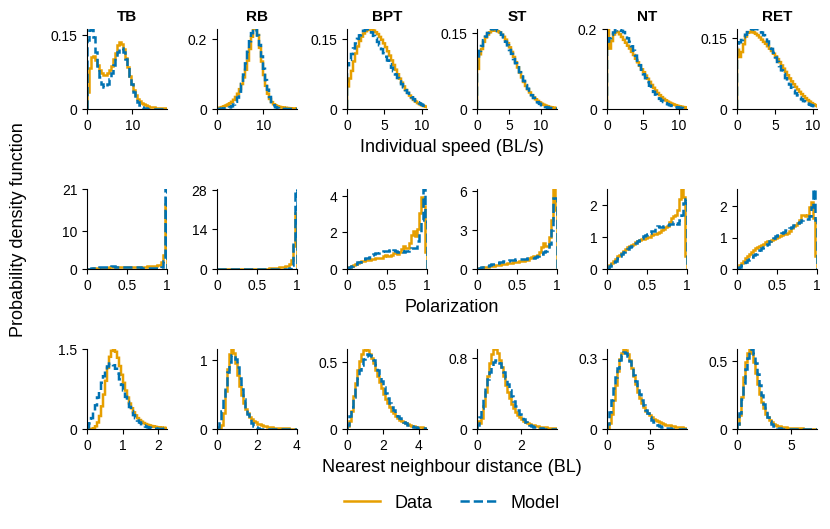

In [3]:
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
                     "xtick.labelsize": 10, "ytick.labelsize": 10})
WIDTH, FONT, lw = 8.27, 13, 1.8                     # A4 width (in), axis labels and legend (pt), line width
COL, LS = ("#E69F00", "#0072B2"), ("-", "--")      # data, model
L, R, T, B, WGAP, HGAP = 0.85, 0.12, 0.40, 0.94, 0.50, 0.80     # margins (top: room for the species names) and gaps (in)
ROWS = [("speed", "Individual speed (BL/s)", 99.5), ("pol", "Polarization", None), ("nnd", "Nearest neighbour distance (BL)", 99)]


def nice_ticks(hi):
    """Two or three round x ticks inside [0, hi]."""
    step = next(s for s in (0.5, 1, 2, 5, 10, 20, 50) if hi / s <= 2.6)
    t = np.arange(0, hi + 1e-9, step)
    return t.astype(int) if step >= 1 else t


def set_y_to_max(ax, ymax):
    """y axis up to the panel's maximum; ticks 0, max/2, max (whole numbers) or 0 and a round number below the max."""
    ax.set_ylim(0, ymax)
    if ymax >= 2:
        yt = sorted({0, int(ymax) // 2, int(ymax)}); ax.set_yticks(yt); ax.set_yticklabels(map(str, yt))
    else:
        k = 10.0 ** np.floor(np.log10(ymax))
        top = max(s * k for s in (1, 1.5, 2, 2.5, 3, 4, 5, 6, 8) if s * k <= ymax * 1.0001)
        ax.set_yticks([0, top]); ax.set_yticklabels(["0", f"{top:.3g}"])


P = (WIDTH - L - R - 5 * WGAP) / 6                 # square panel side (in)
H = T + B + 3 * P + 2 * HGAP
fig = plt.figure(figsize=(WIDTH, H))
gs = GridSpec(3, 6, figure=fig, wspace=WGAP / P, hspace=HGAP / P, left=L / WIDTH, right=1 - R / WIDTH, bottom=B / H, top=1 - T / H)
axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(6)] for i in range(3)])
for i, (key, xlabel, pct) in enumerate(ROWS):
    for j, sp in enumerate(SPECIES):
        ax, d, m = axes[i, j], data[sp][key], model[sp][key]
        hi = np.percentile(d, pct) if pct else 1.0
        edges = np.arange(0, max(d.max(), m.max()) + hi / 40, hi / 40) if pct else np.arange(0, 1.0125, 0.025)
        h = [ax.hist(x, bins=edges, density=True, histtype="step", color=c, ls=ls, lw=lw)[0] for x, c, ls in zip((d, m), COL, LS)]
        inside = edges[:-1] < hi
        ax.set_xlim(0, hi); set_y_to_max(ax, max(hh[inside].max() for hh in h))
        ax.set_xticks(nice_ticks(hi)) if pct else (ax.set_xticks([0, 0.5, 1]), ax.set_xticklabels(["0", "0.5", "1"]))
        ax.spines[["top", "right"]].set_visible(False)
    p0, p1 = axes[i, 0].get_position(), axes[i, -1].get_position()
    fig.text((p0.x0 + p1.x1) / 2, p0.y0 - 0.30 / H, xlabel, ha="center", va="top", fontsize=FONT)              # x label per row
top, bot = axes[0, 0].get_position().y1, axes[2, 0].get_position().y0
fig.text(0.08 / WIDTH, (top + bot) / 2, "Probability density function", rotation=90, ha="left", va="center", fontsize=FONT)
x_mid = (axes[0, 0].get_position().x0 + axes[0, -1].get_position().x1) / 2
fig.legend(handles=[Line2D([], [], color=c, ls=ls, lw=lw, label=lab) for c, ls, lab in zip(COL, LS, ("Data", "Model"))],
           loc="lower center", bbox_to_anchor=(x_mid, 0.04 / H), ncol=2, frameon=False, fontsize=FONT, handlelength=2.0,
           columnspacing=1.5, borderaxespad=0)
for ax, sp in zip(axes[0], SPECIES):                             # species name above each column
    ax.set_title(sp, fontsize=11, fontweight="bold", pad=6)
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(OUT, f"single_species_group_properties_gs16.{ext}"), dpi=300)
plt.show()